# Supervised Sequence Classification

While unsupervised methods can be powerful to identify antigen-specific sequences, being able to leverage known labels to guide the learning process can provide for better results, provided there is a sufficient amount of data to learn from. The first type of supervised learning we will explore within DeepTCR is being able to correctly classify a given TCR sequence to some label (i.e. its antigen specificity) from using its sequence information.

First we will load data from the Murine dataset which has TCR sequences from 9 murine antigens with beta-chain information including sequence, v-beta, and j-beta gene usage.

In [1]:
import sys
sys.path.append('../../')
from DeepTCR.DeepTCR import DeepTCR_SS

# Instantiate training object
DTCR_SS = DeepTCR_SS('Tutorial')

#Load Data from directories
DTCR_SS.Get_Data(directory='../../Data/Murine_Antigens',Load_Prev_Data=False,aggregate_by_aa=True,
               aa_column_beta=0,count_column=1,v_beta_column=2,j_beta_column=3)

Loading Data...


/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/.venv/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


Embedding Sequences...
Data Loaded


We will then train the sequence classifier as follows. First, we will split the dataset into a train,validation,and independent test cohort so we can assess how generalizable our model will be to new unseen data.And then we will train our sequene classifier. Our test_size parameter will tell DeepTCR how much of the data to leave out for valid/test which is split evenly across these two.

In [2]:
DTCR_SS.Get_Train_Valid_Test(test_size=0.25)
DTCR_SS.Train()

Metal device set to: Apple M3 Max


/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:105: UserWarning: `tf.layers.conv2d` is deprecated and will be removed in a future version. Please Use `tf.keras.layers.Conv2D` instead.
  conv = tf.compat.v1.layers.conv2d(inputs, units[ii], (1, kernel), 1, padding='same',
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:107: UserWarning: `tf.layers.flatten` is deprecated and will be removed in a future version. Please use `tf.keras.layers.Flatten` instead.
  conv_out = tf.compat.v1.layers.flatten(tf.reduce_max(input_tensor=conv, axis=2))
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:110: UserWarning: `tf.layers.dropout` is deprecated and will be removed in a future version. Please use `tf.keras.layers.Dropout` instead.
  conv = tf.compat.v1.layers.dropout(conv, prob)
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/


Training_Statistics: 
 Epoch: 1 Training loss: 2.20914 Validation loss: 2.15765 Testing loss: 2.17350 Training Accuracy: 0.12576 Validation Accuracy: 0.2 Testing AUC: 0.50444
Training_Statistics: 
 Epoch: 2 Training loss: 2.13392 Validation loss: 2.08983 Testing loss: 2.10481 Training Accuracy: 0.26974 Validation Accuracy: 0.31803 Testing AUC: 0.53067
Training_Statistics: 
 Epoch: 3 Training loss: 2.06396 Validation loss: 2.01249 Testing loss: 2.02740 Training Accuracy: 0.34947 Validation Accuracy: 0.3377 Testing AUC: 0.55349
Training_Statistics: 
 Epoch: 4 Training loss: 1.97846 Validation loss: 1.92780 Testing loss: 1.94338 Training Accuracy: 0.3876 Validation Accuracy: 0.36066 Testing AUC: 0.57566
Training_Statistics: 
 Epoch: 5 Training loss: 1.89599 Validation loss: 1.85793 Testing loss: 1.87548 Training Accuracy: 0.36668 Validation Accuracy: 0.3541 Testing AUC: 0.5969
Training_Statistics: 
 Epoch: 6 Training loss: 1.84050 Validation loss: 1.84217 Testing loss: 1.86148 Training A

Training_Statistics: 
 Epoch: 46/10000 Training loss: 1.01209 Validation loss: 1.33730 Testing loss: 1.24025 Training Accuracy: 0.66878 Validation Accuracy: 0.52787 Testing AUC: 0.83979
Training_Statistics: 
 Epoch: 47/10000 Training loss: 1.00376 Validation loss: 1.33297 Testing loss: 1.23769 Training Accuracy: 0.66832 Validation Accuracy: 0.53443 Testing AUC: 0.84041
Training_Statistics: 
 Epoch: 48/10000 Training loss: 0.98702 Validation loss: 1.33136 Testing loss: 1.23639 Training Accuracy: 0.68198 Validation Accuracy: 0.54426 Testing AUC: 0.84129
Training_Statistics: 
 Epoch: 49/10000 Training loss: 0.97562 Validation loss: 1.33256 Testing loss: 1.23684 Training Accuracy: 0.68079 Validation Accuracy: 0.53115 Testing AUC: 0.84243
Training_Statistics: 
 Epoch: 50/10000 Training loss: 0.96215 Validation loss: 1.32804 Testing loss: 1.23471 Training Accuracy: 0.68079 Validation Accuracy: 0.5377 Testing AUC: 0.84259
Training_Statistics: 
 Epoch: 51/10000 Training loss: 0.94967 Validatio

When we are done training, we can assess how well our classifier performs on the independent test set via looking at the ROC curves.

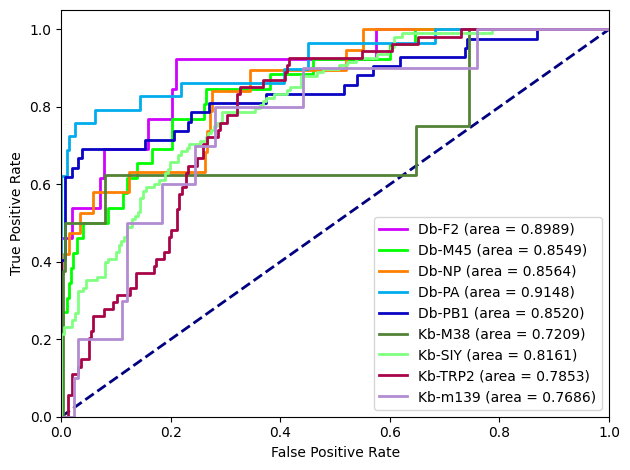

In [3]:
DTCR_SS.AUC_Curve()

We can also train our classifier with two other methods that allow for multiple iterations including a Monte Carlo method and K-Fold Cross-Validation Method.

For the Monte-Carlo method, we will specify the number of times we want to train train the classifier and the test size we want for each iteration. Of note, all parameters available for the Train method are also inputs for the Monte-Carlo and K-Fold Cross-Validation method.

In [4]:
DTCR_SS.Monte_Carlo_CrossVal(test_size=0.25,folds=5)

/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:105: UserWarning: `tf.layers.conv2d` is deprecated and will be removed in a future version. Please Use `tf.keras.layers.Conv2D` instead.
  conv = tf.compat.v1.layers.conv2d(inputs, units[ii], (1, kernel), 1, padding='same',
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:107: UserWarning: `tf.layers.flatten` is deprecated and will be removed in a future version. Please use `tf.keras.layers.Flatten` instead.
  conv_out = tf.compat.v1.layers.flatten(tf.reduce_max(input_tensor=conv, axis=2))
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:110: UserWarning: `tf.layers.dropout` is deprecated and will be removed in a future version. Please use `tf.keras.layers.Dropout` instead.
  conv = tf.compat.v1.layers.dropout(conv, prob)
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/

Fold 0

Training_Statistics: 
 Epoch: 1 Training loss: 2.15378 Validation loss: 2.08227 Testing loss: 2.09648 Training Accuracy: 0.17311 Validation Accuracy: 0.34754 Testing AUC: 0.5528
Training_Statistics: 
 Epoch: 2 Training loss: 2.06097 Validation loss: 1.99905 Testing loss: 2.01552 Training Accuracy: 0.36123 Validation Accuracy: 0.38033 Testing AUC: 0.57024
Training_Statistics: 
 Epoch: 3 Training loss: 1.97849 Validation loss: 1.91579 Testing loss: 1.93499 Training Accuracy: 0.37011 Validation Accuracy: 0.35738 Testing AUC: 0.58909
Training_Statistics: 
 Epoch: 4 Training loss: 1.89036 Validation loss: 1.84876 Testing loss: 1.87252 Training Accuracy: 0.35601 Validation Accuracy: 0.3541 Testing AUC: 0.6043
Training_Statistics: 
 Epoch: 5 Training loss: 1.83544 Validation loss: 1.83376 Testing loss: 1.86339 Training Accuracy: 0.35634 Validation Accuracy: 0.3541 Testing AUC: 0.61946
Training_Statistics: 
 Epoch: 6 Training loss: 1.82978 Validation loss: 1.81694 Testing loss: 1.84913

 20%|██████████████▌                                                          | 1/5 [00:04<00:17,  4.35s/it]


Train Accuracy = 0.71, Valid Accuracy = 0.52, Test Accuracy = 0.54, 
Train AUC = 0.94, Valid AUC = 0.85, Test AUC = 0.84, 

Per Class AUC
Train: Db-F2 = 0.96, Db-M45 = 0.97, Db-NP = 0.92, Db-PA = 0.98, Db-PB1 = 0.95, Kb-M38 = 0.94, Kb-SIY = 0.92, Kb-TRP2 = 0.90, Kb-m139 = 0.94, 
Valid: Db-F2 = 0.93, Db-M45 = 0.85, Db-NP = 0.82, Db-PA = 0.93, Db-PB1 = 0.87, Kb-M38 = 0.90, Kb-SIY = 0.81, Kb-TRP2 = 0.76, Kb-m139 = 0.76, 
Test: Db-F2 = 0.90, Db-M45 = 0.94, Db-NP = 0.83, Db-PA = 0.90, Db-PB1 = 0.90, Kb-M38 = 0.70, Kb-SIY = 0.82, Kb-TRP2 = 0.75, Kb-m139 = 0.82, 


Fold 1

Training_Statistics: 
 Epoch: 1 Training loss: 2.21073 Validation loss: 2.14175 Testing loss: 2.13920 Training Accuracy: 0.10404 Validation Accuracy: 0.25246 Testing AUC: 0.51101
Training_Statistics: 
 Epoch: 2 Training loss: 2.10928 Validation loss: 2.04946 Testing loss: 2.04915 Training Accuracy: 0.28464 Validation Accuracy: 0.34098 Testing AUC: 0.52684
Training_Statistics: 
 Epoch: 3 Training loss: 2.02069 Validation lo

 40%|█████████████████████████████▏                                           | 2/5 [00:09<00:14,  4.90s/it]


Train Accuracy = 0.73, Valid Accuracy = 0.55, Test Accuracy = 0.57, 
Train AUC = 0.95, Valid AUC = 0.85, Test AUC = 0.86, 

Per Class AUC
Train: Db-F2 = 0.97, Db-M45 = 0.97, Db-NP = 0.94, Db-PA = 0.98, Db-PB1 = 0.96, Kb-M38 = 0.94, Kb-SIY = 0.92, Kb-TRP2 = 0.91, Kb-m139 = 0.95, 
Valid: Db-F2 = 0.92, Db-M45 = 0.86, Db-NP = 0.79, Db-PA = 0.92, Db-PB1 = 0.89, Kb-M38 = 0.88, Kb-SIY = 0.83, Kb-TRP2 = 0.79, Kb-m139 = 0.81, 
Test: Db-F2 = 0.89, Db-M45 = 0.91, Db-NP = 0.83, Db-PA = 0.94, Db-PB1 = 0.90, Kb-M38 = 0.84, Kb-SIY = 0.84, Kb-TRP2 = 0.76, Kb-m139 = 0.82, 


Fold 2

Training_Statistics: 
 Epoch: 1 Training loss: 2.16444 Validation loss: 2.09203 Testing loss: 2.10281 Training Accuracy: 0.18676 Validation Accuracy: 0.32131 Testing AUC: 0.61457
Training_Statistics: 
 Epoch: 2 Training loss: 2.07525 Validation loss: 2.00582 Testing loss: 2.01851 Training Accuracy: 0.35075 Validation Accuracy: 0.34426 Testing AUC: 0.62642
Training_Statistics: 
 Epoch: 3 Training loss: 1.98799 Validation lo

... (3 outputs left out)


Train Accuracy = 0.72, Valid Accuracy = 0.55, Test Accuracy = 0.56, 
Train AUC = 0.95, Valid AUC = 0.84, Test AUC = 0.85, 

Per Class AUC
Train: Db-F2 = 0.96, Db-M45 = 0.96, Db-NP = 0.93, Db-PA = 0.98, Db-PB1 = 0.96, Kb-M38 = 0.95, Kb-SIY = 0.92, Kb-TRP2 = 0.90, Kb-m139 = 0.94, 
Valid: Db-F2 = 0.90, Db-M45 = 0.87, Db-NP = 0.78, Db-PA = 0.93, Db-PB1 = 0.88, Kb-M38 = 0.85, Kb-SIY = 0.82, Kb-TRP2 = 0.78, Kb-m139 = 0.78, 
Test: Db-F2 = 0.90, Db-M45 = 0.89, Db-NP = 0.82, Db-PA = 0.92, Db-PB1 = 0.89, Kb-M38 = 0.79, Kb-SIY = 0.83, Kb-TRP2 = 0.77, Kb-m139 = 0.83, 


Fold 4

Training_Statistics: 
 Epoch: 1 Training loss: 2.20861 Validation loss: 2.13468 Testing loss: 2.12880 Training Accuracy: 0.10623 Validation Accuracy: 0.27541 Testing AUC: 0.49175
Training_Statistics: 
 Epoch: 2 Training loss: 2.10829 Validation loss: 2.04005 Testing loss: 2.03727 Training Accuracy: 0.30965 Validation Accuracy: 0.37705 Testing AUC: 0.5131
Training_Statistics: 
 Epoch: 3 Training loss: 2.01217 Validation los

100%|█████████████████████████████████████████████████████████████████████████| 5/5 [00:23<00:00,  4.61s/it]


Train Accuracy = 0.72, Valid Accuracy = 0.56, Test Accuracy = 0.56, 
Train AUC = 0.94, Valid AUC = 0.84, Test AUC = 0.85, 

Per Class AUC
Train: Db-F2 = 0.96, Db-M45 = 0.96, Db-NP = 0.93, Db-PA = 0.98, Db-PB1 = 0.96, Kb-M38 = 0.94, Kb-SIY = 0.92, Kb-TRP2 = 0.90, Kb-m139 = 0.94, 
Valid: Db-F2 = 0.90, Db-M45 = 0.88, Db-NP = 0.79, Db-PA = 0.93, Db-PB1 = 0.86, Kb-M38 = 0.85, Kb-SIY = 0.83, Kb-TRP2 = 0.78, Kb-m139 = 0.75, 
Test: Db-F2 = 0.91, Db-M45 = 0.89, Db-NP = 0.81, Db-PA = 0.92, Db-PB1 = 0.89, Kb-M38 = 0.81, Kb-SIY = 0.82, Kb-TRP2 = 0.77, Kb-m139 = 0.83, 


Monte Carlo Simulation Completed


Training_Statistics: 
 Epoch: 52/10000 Training loss: 0.92828 Validation loss: 1.28068 Testing loss: 1.28418 Training Accuracy: 0.68851 Validation Accuracy: 0.5541 Testing AUC: 0.85856
Training_Statistics: 
 Epoch: 53/10000 Training loss: 0.91381 Validation loss: 1.28659 Testing loss: 1.27971 Training Accuracy: 0.68751 Validation Accuracy: 0.55738 Testing AUC: 0.85987
Training_Statistics: 
 Epoch: 54/10000 Training loss: 0.90699 Validation loss: 1.28006 Testing loss: 1.27409 Training Accuracy: 0.68568 Validation Accuracy: 0.57377 Testing AUC: 0.86166
Training_Statistics: 
 Epoch: 55/10000 Training loss: 0.88953 Validation loss: 1.28709 Testing loss: 1.27960 Training Accuracy: 0.70494 Validation Accuracy: 0.57049 Testing AUC: 0.86145
Training_Statistics: 
 Epoch: 56/10000 Training loss: 0.88062 Validation loss: 1.28079 Testing loss: 1.27437 Training Accuracy: 0.69801 Validation Accuracy: 0.57049 Testing AUC: 0.86207
Training_Statistics: 
 Epoch: 57/10000 Training loss: 0.86859 Validatio

Once again, we can view the AUC curve.

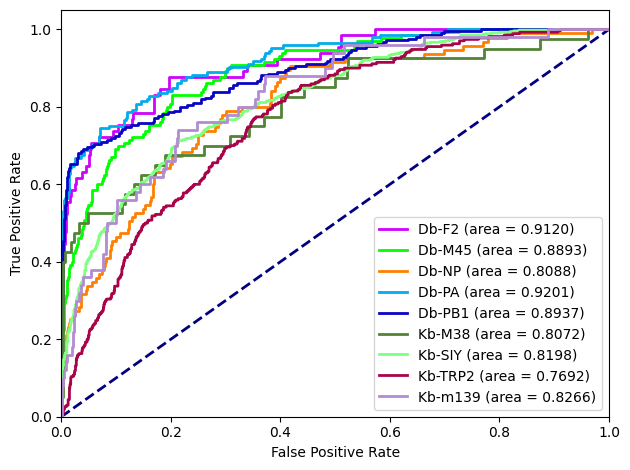

In [5]:
DTCR_SS.AUC_Curve()

To run a K-fold cross validation with 5 folds of the data, fun the following command. In this case, no test_size is required as the algorithm is trained on the entirety of the train folds and tested on the out-fold.

In [6]:
DTCR_SS.K_Fold_CrossVal(folds=5)

/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:105: UserWarning: `tf.layers.conv2d` is deprecated and will be removed in a future version. Please Use `tf.keras.layers.Conv2D` instead.
  conv = tf.compat.v1.layers.conv2d(inputs, units[ii], (1, kernel), 1, padding='same',
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:107: UserWarning: `tf.layers.flatten` is deprecated and will be removed in a future version. Please use `tf.keras.layers.Flatten` instead.
  conv_out = tf.compat.v1.layers.flatten(tf.reduce_max(input_tensor=conv, axis=2))
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/Layers.py:110: UserWarning: `tf.layers.dropout` is deprecated and will be removed in a future version. Please use `tf.keras.layers.Dropout` instead.
  conv = tf.compat.v1.layers.dropout(conv, prob)
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/functions/

Fold 0

Training_Statistics: 
 Epoch: 1 Training loss: 2.18673 Validation loss: 2.12009 Testing loss: 2.11562 Training Accuracy: 0.15979 Validation Accuracy: 0.29569 Testing AUC: 0.52129
Training_Statistics: 
 Epoch: 2 Training loss: 2.08343 Validation loss: 2.02736 Testing loss: 2.01539 Training Accuracy: 0.34497 Validation Accuracy: 0.32238 Testing AUC: 0.55108
Training_Statistics: 
 Epoch: 3 Training loss: 1.96712 Validation loss: 1.95205 Testing loss: 1.93031 Training Accuracy: 0.37338 Validation Accuracy: 0.32238 Testing AUC: 0.57413
Training_Statistics: 
 Epoch: 4 Training loss: 1.86599 Validation loss: 1.96308 Testing loss: 1.93071 Training Accuracy: 0.37628 Validation Accuracy: 0.32238 Testing AUC: 0.59301
Training_Statistics: 
 Epoch: 5 Training loss: 1.86688 Validation loss: 1.94432 Testing loss: 1.91286 Training Accuracy: 0.37338 Validation Accuracy: 0.32238 Testing AUC: 0.61765
Training_Statistics: 
 Epoch: 6 Training loss: 1.83773 Validation loss: 1.88185 Testing loss: 1.8

Training_Statistics: 
 Epoch: 47/10000 Training loss: 0.96717 Validation loss: 1.36468 Testing loss: 1.32359 Training Accuracy: 0.66821 Validation Accuracy: 0.55236 Testing AUC: 0.83189
Training_Statistics: 
 Epoch: 48/10000 Training loss: 0.93214 Validation loss: 1.36310 Testing loss: 1.33099 Training Accuracy: 0.67857 Validation Accuracy: 0.53799 Testing AUC: 0.83243
Training_Statistics: 
 Epoch: 49/10000 Training loss: 0.92472 Validation loss: 1.37199 Testing loss: 1.32486 Training Accuracy: 0.66795 Validation Accuracy: 0.55441 Testing AUC: 0.83136
Training_Statistics: 
 Epoch: 50/10000 Training loss: 0.91818 Validation loss: 1.37324 Testing loss: 1.32258 Training Accuracy: 0.68323 Validation Accuracy: 0.53799 Testing AUC: 0.83212
Training_Statistics: 
 Epoch: 51/10000 Training loss: 0.89758 Validation loss: 1.36574 Testing loss: 1.32715 Training Accuracy: 0.68689 Validation Accuracy: 0.54415 Testing AUC: 0.83461
Done Training
Accuracy = 0.5215605749486653
1
Training_Statistics: 
 E

Training_Statistics: 
 Epoch: 44/10000 Training loss: 0.99729 Validation loss: 1.37765 Testing loss: 1.24509 Training Accuracy: 0.65827 Validation Accuracy: 0.52977 Testing AUC: 0.82907
Training_Statistics: 
 Epoch: 45/10000 Training loss: 0.98363 Validation loss: 1.37739 Testing loss: 1.24299 Training Accuracy: 0.65531 Validation Accuracy: 0.53593 Testing AUC: 0.82982
Training_Statistics: 
 Epoch: 46/10000 Training loss: 0.98145 Validation loss: 1.37276 Testing loss: 1.24268 Training Accuracy: 0.66129 Validation Accuracy: 0.54004 Testing AUC: 0.82951
Training_Statistics: 
 Epoch: 47/10000 Training loss: 0.94712 Validation loss: 1.37948 Testing loss: 1.25008 Training Accuracy: 0.67649 Validation Accuracy: 0.52567 Testing AUC: 0.82817
Training_Statistics: 
 Epoch: 48/10000 Training loss: 0.94200 Validation loss: 1.38699 Testing loss: 1.24391 Training Accuracy: 0.67227 Validation Accuracy: 0.54004 Testing AUC: 0.82817
Training_Statistics: 
 Epoch: 49/10000 Training loss: 0.93907 Validati

Training_Statistics: 
 Epoch: 36/10000 Training loss: 1.12718 Validation loss: 1.28148 Testing loss: 1.29186 Training Accuracy: 0.62786 Validation Accuracy: 0.56879 Testing AUC: 0.83361
Training_Statistics: 
 Epoch: 37/10000 Training loss: 1.08543 Validation loss: 1.27776 Testing loss: 1.28438 Training Accuracy: 0.6341 Validation Accuracy: 0.56468 Testing AUC: 0.83661
Training_Statistics: 
 Epoch: 38/10000 Training loss: 1.06171 Validation loss: 1.27973 Testing loss: 1.28247 Training Accuracy: 0.65137 Validation Accuracy: 0.57495 Testing AUC: 0.83845
Training_Statistics: 
 Epoch: 39/10000 Training loss: 1.04762 Validation loss: 1.27495 Testing loss: 1.27952 Training Accuracy: 0.65937 Validation Accuracy: 0.56879 Testing AUC: 0.83858
Training_Statistics: 
 Epoch: 40/10000 Training loss: 1.03837 Validation loss: 1.26853 Testing loss: 1.27424 Training Accuracy: 0.66353 Validation Accuracy: 0.56674 Testing AUC: 0.83936
Training_Statistics: 
 Epoch: 41/10000 Training loss: 1.02816 Validatio

Training_Statistics: 
 Epoch: 26/10000 Training loss: 1.35026 Validation loss: 1.40073 Testing loss: 1.40014 Training Accuracy: 0.54014 Validation Accuracy: 0.48871 Testing AUC: 0.81001
Training_Statistics: 
 Epoch: 27/10000 Training loss: 1.32383 Validation loss: 1.38425 Testing loss: 1.38188 Training Accuracy: 0.54356 Validation Accuracy: 0.48255 Testing AUC: 0.81127
Training_Statistics: 
 Epoch: 28/10000 Training loss: 1.29567 Validation loss: 1.36892 Testing loss: 1.36797 Training Accuracy: 0.54042 Validation Accuracy: 0.49487 Testing AUC: 0.81351
Training_Statistics: 
 Epoch: 29/10000 Training loss: 1.27354 Validation loss: 1.35907 Testing loss: 1.36172 Training Accuracy: 0.55664 Validation Accuracy: 0.50308 Testing AUC: 0.81567
Training_Statistics: 
 Epoch: 30/10000 Training loss: 1.25292 Validation loss: 1.35208 Testing loss: 1.35494 Training Accuracy: 0.572 Validation Accuracy: 0.50924 Testing AUC: 0.81804
Training_Statistics: 
 Epoch: 31/10000 Training loss: 1.22439 Validation

Training_Statistics: 
 Epoch: 24/10000 Training loss: 1.34514 Validation loss: 1.45771 Testing loss: 1.38241 Training Accuracy: 0.53423 Validation Accuracy: 0.48255 Testing AUC: 0.8317
Training_Statistics: 
 Epoch: 25/10000 Training loss: 1.34173 Validation loss: 1.44403 Testing loss: 1.36754 Training Accuracy: 0.5263 Validation Accuracy: 0.49076 Testing AUC: 0.83266
Training_Statistics: 
 Epoch: 26/10000 Training loss: 1.29992 Validation loss: 1.43743 Testing loss: 1.35550 Training Accuracy: 0.54775 Validation Accuracy: 0.48665 Testing AUC: 0.83381
Training_Statistics: 
 Epoch: 27/10000 Training loss: 1.27871 Validation loss: 1.43357 Testing loss: 1.34732 Training Accuracy: 0.54882 Validation Accuracy: 0.48665 Testing AUC: 0.83498
Training_Statistics: 
 Epoch: 28/10000 Training loss: 1.24969 Validation loss: 1.42393 Testing loss: 1.33728 Training Accuracy: 0.56192 Validation Accuracy: 0.49281 Testing AUC: 0.8364
Training_Statistics: 
 Epoch: 29/10000 Training loss: 1.26411 Validation 

Once our algorithm has been trained, we may want to see which sequences are the most strongly predicted for each label. To do this we will run the following command. The output of the command is a dictionary of dataframes within the object we can view. Additionally, these dataframes can be found in the results folder underneath the subdirectory 'Rep_Sequences'.

In [7]:
DTCR_SS.Representative_Sequences()

In [8]:
print(DTCR_SS.Rep_Seq['Db-F2'])

   alpha             beta v_alpha j_alpha      v_beta d_beta      j_beta  \
98  None    CASSIGDTYEQYF    None    None  TCRBV19-01   None  TCRBJ02-07   
13  None  CASSPGTGGTERLFF    None    None  TCRBV19-03   None  TCRBJ01-04   
11  None   CASSPGTGDTEVFF    None    None  TCRBV19-03   None  TCRBJ01-01   
69  None   CASSAGQVNTEVFF    None    None  TCRBV19-03   None  TCRBJ01-01   
31  None    CASSPGTNTEVFF    None    None  TCRBV19-03   None  TCRBJ01-01   
18  None    CASSPGQYTEVFF    None    None  TCRBV19-03   None  TCRBJ01-01   
83  None    CASSMGANTEVFF    None    None  TCRBV19-01   None  TCRBJ01-01   
21  None   CASSPGQDYTEVFF    None    None  TCRBV19-03   None  TCRBJ01-01   
26  None    CASSPGANTEVFF    None    None  TCRBV19-03   None  TCRBJ01-01   
28  None    CASSPGQNTEVFF    None    None  TCRBV19-03   None  TCRBJ01-01   

    Class     Sample      Freq  ...           HLA     Db-F2    Db-M45  \
98  Db-F2  Db-F2.tsv  0.008547  ...  [N, o, n, e]  0.852010  0.019202   
13  Db-F2  Db-F2.

Furthermore, we may want to know which learned motifs are associated with a given label. To do this, we can run the following command with the label we want to know the predictive motifs for.

In [9]:
DTCR_SS.Motif_Identification('Db-F2')

Motif Identification Completed


The motifs can then be found in fasta files in the results folder underneath (label)_(alpha/beta)_Motifs. These fasta fiels can then be used with "https://weblogo.berkeley.edu/logo.cgi" for motif visualization.The file names have the magnitude of the enrichment as the first number followed by '_feature_n'. The higher the number, the more enriched the motif is in the label-specific sequences.

## Visualization

We can also visualize the learned latent space from the supervised sequence classifier through plotting a UMAP representation of the sequences in two dimensions.

In [13]:
DTCR_SS.UMAP_Plot(by_class=True,freq_weight=True,scale=1000)

We can also specify whether we only want to plot sequences that were used in either train,valid, or the test set with the 'set' parameter.

In [14]:
DTCR_SS.UMAP_Plot(by_class=True,freq_weight=True,scale=2000,set='test')

We can also visualize how the repertoires are related from this learned representation. This visualiztion is helpful when we want to compare how different TCR repertoires are related structurally.

In [15]:
DTCR_SS.Repertoire_Dendrogram(gridsize=50,gaussian_sigma=0.75,lw=6,dendrogram_radius=0.3)

UMAP transformation...
PhenoGraph Clustering...
Finding 30 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 0.02037787437438965 seconds
Jaccard graph constructed in 0.3242659568786621 seconds
Wrote graph to binary file in 0.014750003814697266 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.895529
Louvain completed 21 runs in 1.4164280891418457 seconds
PhenoGraph complete in 1.7812528610229492 seconds
Clustering Done


See documentation for how to use the full functionality of this method.